# **Lab 7(B) - Mathematical and Statistical Filters (Color Image)**

Name: Abdulrahman Saleh Alaamri
ID: 2240002427

This uses the color noise.jpg image. The noise is added to each channel and the filters run on R, G and B separately.

In [1]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)
np.random.seed(0)  # same noise every run

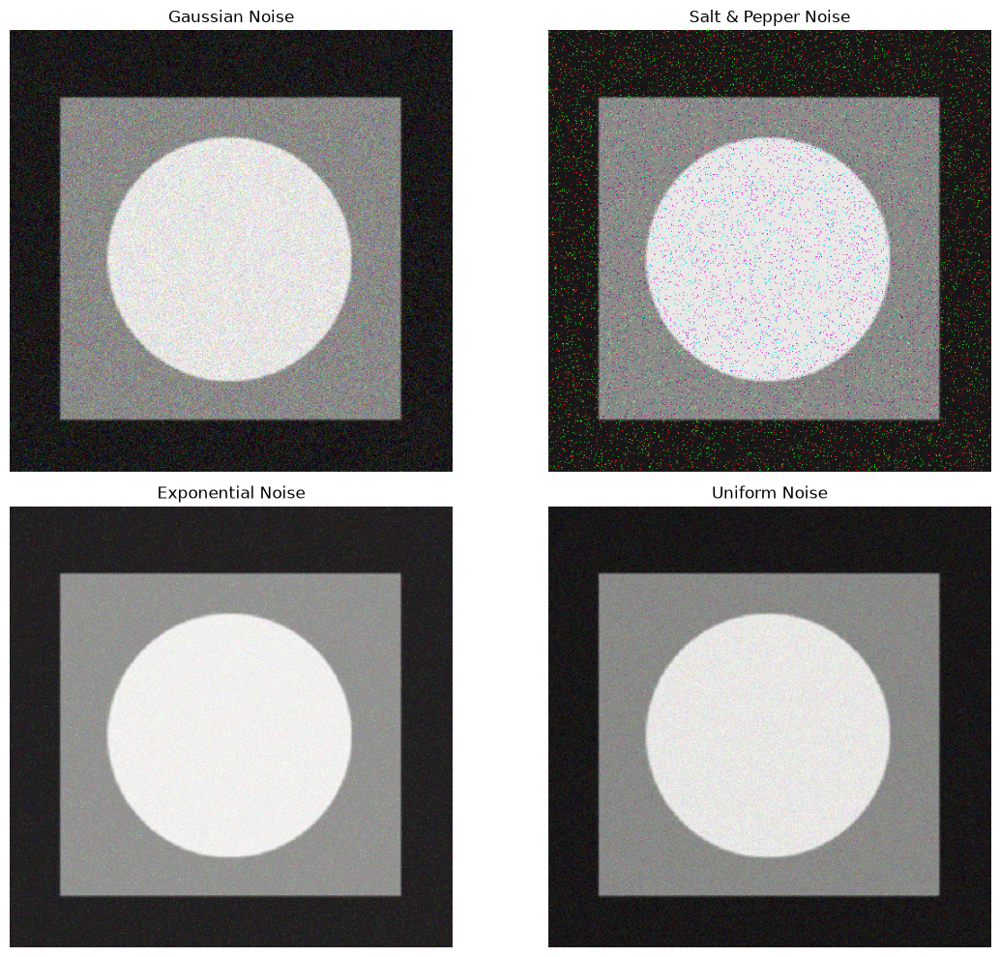

In [2]:
# ========== ( Adding noise to a color Image ) =================

# 0. Read an Image in color and convert BGR -> RGB
imgPath = 'noise.jpg'
img = cv2.cvtColor(cv2.imread(imgPath, 1), cv2.COLOR_BGR2RGB)

# 1. Function that handles all noise types (Gaussian, Exp, Uniform & Salt&Pepper)
# image.shape is (rows, cols, 3) so every channel gets its own noise
def add_noise(image, noise_type):
    if noise_type == "gaussian":
        mean = 0
        var = 0.01  # Adjust for more/less noise
        sigma = var**0.5
        gauss = np.random.normal(mean, sigma, image.shape)
        noisy = image / 255 + gauss
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)

    elif noise_type == "salt_pepper":
        s_vs_p = 0.5
        amount = 0.04
        noisy = np.copy(image)
        # Salt (white values), coords has one index array for rows, cols and channels
        num_salt = np.ceil(amount * image.size * s_vs_p)
        coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
        noisy[tuple(coords)] = 255
        # Pepper (black values)
        num_pepper = np.ceil(amount * image.size * (1.0 - s_vs_p))
        coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
        noisy[tuple(coords)] = 0
        return noisy

    elif noise_type == "exponential":
        expo = np.random.exponential(scale=10.0, size=image.shape)
        noisy = image + expo
        return np.clip(noisy, 0, 255).astype(np.uint8)

    elif noise_type == "uniform":
        low = -20
        high = 20
        uni = np.random.uniform(low, high, image.shape)
        noisy = image + uni
        return np.clip(noisy, 0, 255).astype(np.uint8)


# 2. Generate Noisy Images
noise_gauss = add_noise(img, "gaussian")
noise_sp = add_noise(img, "salt_pepper")
noise_expo = add_noise(img, "exponential")
noise_uni = add_noise(img, "uniform")

# 3. Display in 2x2 Grid
plt.figure(figsize=(12, 10))

plt.subplot(221), plt.imshow(noise_gauss), plt.title('Gaussian Noise')
plt.subplot(222), plt.imshow(noise_sp), plt.title('Salt & Pepper Noise')
plt.subplot(223), plt.imshow(noise_expo), plt.title('Exponential Noise')
plt.subplot(224), plt.imshow(noise_uni), plt.title('Uniform Noise')

for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

## **Arithmetic Mean**

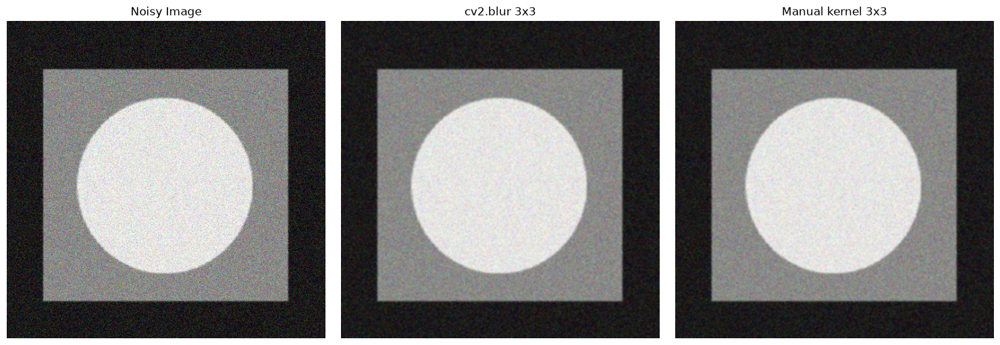

Max difference between the two methods: 0


In [3]:
# --- METHOD 1: Using Built-in OpenCV function ---
filtered_img = cv2.blur(noise_gauss, (3, 3))

# --- METHOD 2: Manual implementation using a Kernel ---
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
arithmetic_mean_manual = cv2.filter2D(noise_gauss, -1, kernel)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_gauss), plt.title('Noisy Image')
plt.subplot(132), plt.imshow(filtered_img), plt.title('cv2.blur 3x3')
plt.subplot(133), plt.imshow(arithmetic_mean_manual), plt.title('Manual kernel 3x3')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

print("Max difference between the two methods:", np.abs(filtered_img.astype(int) - arithmetic_mean_manual).max())

## **Geometric Means**

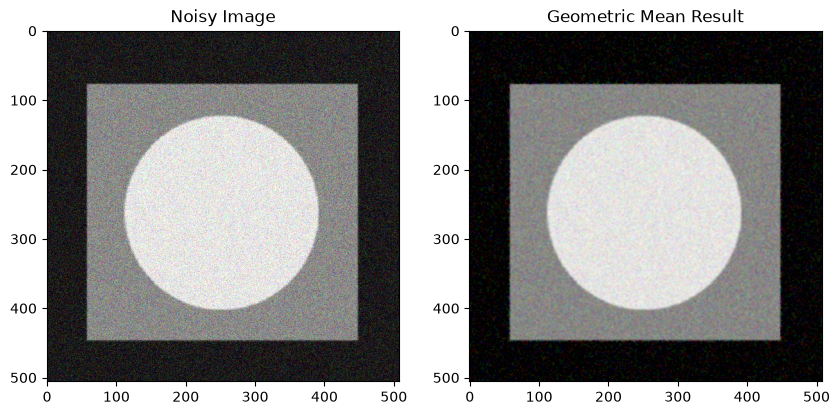

In [4]:
def geometric_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 and add a tiny epsilon to avoid log(0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Apply the log-transform
    log_img = np.log(img_float)

    # 3. Apply a box filter to the log image (average of logs, per channel)
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    mean_log = cv2.filter2D(log_img, -1, kernel)

    # 4. Take the exponent to get back to the geometric mean
    geo_mean = np.exp(mean_log)

    # 5. Clip and convert back to 8-bit
    return np.clip(geo_mean, 0, 255).astype(np.uint8)

# === List of noisy images
# noise_gauss, noise_sp, noise_expo, noise_uni
noise_img = noise_gauss

result = geometric_mean_filter(noise_img, kernel_size=3)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(result), plt.title('Geometric Mean Result')
plt.show()

## **Harmonic Means Filter**

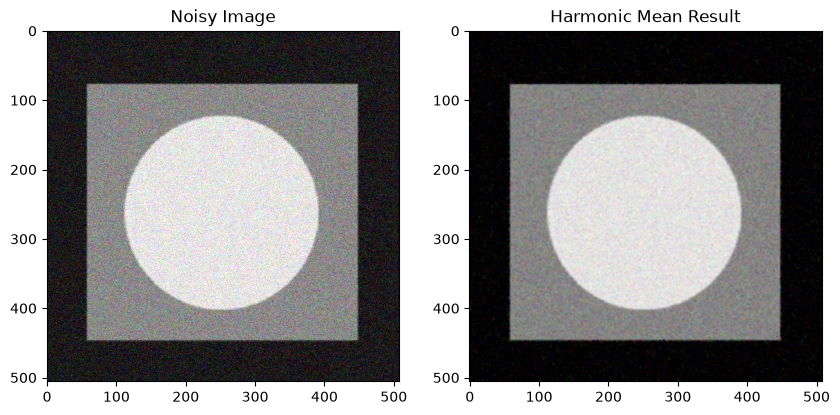

In [5]:
def harmonic_mean_filter(image, kernel_size=3):
    # 1. Convert to float64, add a tiny epsilon to handle black pixels (0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Reciprocal of every value (1/P)
    reciprocal_img = 1.0 / img_float

    # 3. Sum the reciprocals in the window (per channel)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)

    # 4. (Window Size) / Sum of Reciprocals
    n = kernel_size * kernel_size
    harmonic_mean = n / sum_reciprocal

    # 5. Clip the results and convert back to 8-bit
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)

# === List of noisy images
# noise_gauss, noise_sp, noise_expo, noise_uni
noise_img = noise_gauss

cleaned_img = harmonic_mean_filter(noise_img, kernel_size=3)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(cleaned_img), plt.title('Harmonic Mean Result')
plt.show()

## **Contra - Harmonic Mean Filter**

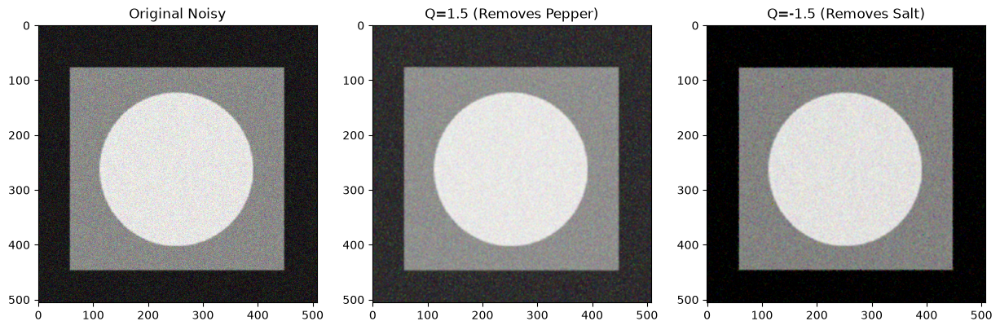

In [6]:
def contra_harmonic_mean(image, kernel_size=3, Q=0):
    # 1. Convert to float to handle high powers and prevent overflow
    img_float = image.astype(np.float64) + 1e-6

    # 2. Numerator: sum of pixels to the power (Q + 1)
    numerator = np.power(img_float, Q + 1)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    num_sum = cv2.filter2D(numerator, -1, kernel)

    # 3. Denominator: sum of pixels to the power Q
    denominator = np.power(img_float, Q)
    den_sum = cv2.filter2D(denominator, -1, kernel)

    # 4. Divide, avoiding division by zero
    result = num_sum / (den_sum + 1e-6)

    return np.clip(result, 0, 255).astype(np.uint8)

# === List of noisy images
# noise_gauss, noise_sp, noise_expo, noise_uni
noise_img = noise_gauss

# Q > 0 (e.g., 1.5): Removes Pepper Noise (black spots)
pepper_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=1.5)

# Q < 0 (e.g., -1.5): Removes Salt Noise (white spots)
salt_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=-1.5)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_img), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(pepper_removed), plt.title('Q=1.5 (Removes Pepper)')
plt.subplot(133), plt.imshow(salt_removed), plt.title('Q=-1.5 (Removes Salt)')
plt.show()

## **Median Filter**

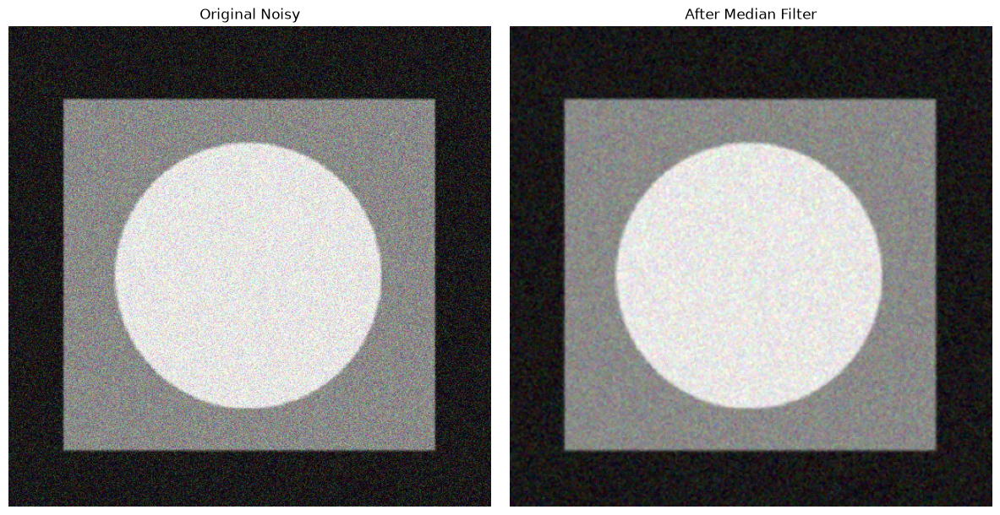

In [7]:
# === List of noisy images
# noise_gauss, noise_sp, noise_expo, noise_uni
noise_img = noise_gauss

# ksize MUST be an odd integer (3, 5, 7, ...); medianBlur works on each channel
median_result = cv2.medianBlur(noise_img, 3)

plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(noise_img), plt.title('Original Noisy'), plt.axis('off')
plt.subplot(122), plt.imshow(median_result), plt.title('After Median Filter'), plt.axis('off')
plt.tight_layout()
plt.show()

## **Max and Min Filter**

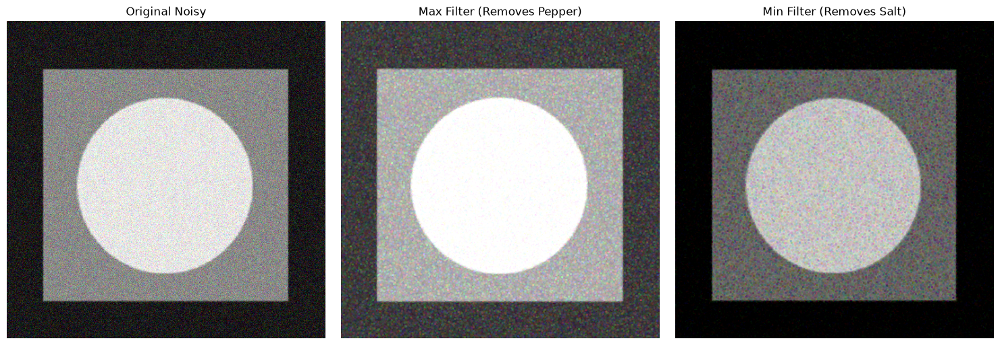

In [8]:
# === List of noisy images
# noise_gauss, noise_sp, noise_expo, noise_uni
noise_img = noise_gauss

kernel = np.ones((3, 3), np.uint8)

# Max filter (dilation): brightest value in the neighborhood, per channel
max_filter = cv2.dilate(noise_img, kernel)

# Min filter (erosion): darkest value in the neighborhood, per channel
min_filter = cv2.erode(noise_img, kernel)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_img), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(max_filter), plt.title('Max Filter (Removes Pepper)')
plt.subplot(133), plt.imshow(min_filter), plt.title('Min Filter (Removes Salt)')

for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

## **Mid-Point Filtering**

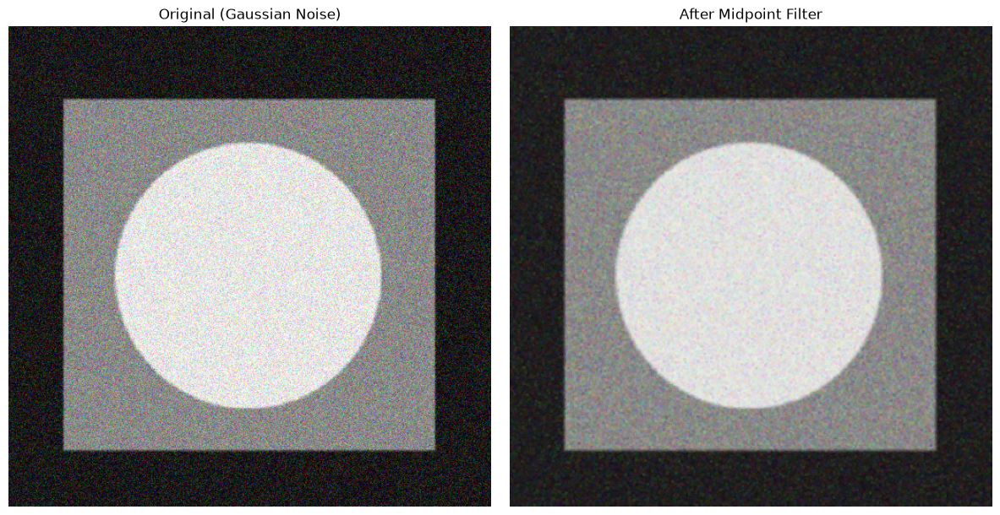

In [9]:
def midpoint_filter(image, kernel_size=3):
    kernel = np.ones((kernel_size, kernel_size), np.uint8)

    # Max and min of the neighborhood (per channel)
    max_img = cv2.dilate(image, kernel).astype(np.float64)
    min_img = cv2.erode(image, kernel).astype(np.float64)

    # Average of Max and Min
    midpoint = (max_img + min_img) / 2

    return midpoint.astype(np.uint8)

# === List of noisy images
# noise_gauss, noise_sp, noise_expo, noise_uni
noise_img = noise_gauss

result = midpoint_filter(noise_img, kernel_size=3)

plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(noise_img), plt.title('Original (Gaussian Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(result), plt.title('After Midpoint Filter'), plt.axis('off')
plt.tight_layout()
plt.show()

## **Salt & Pepper Noise**

The filters above use the gaussian noise image, but median, max/min and contra-harmonic are made for salt & pepper noise, so I ran them on that image here. The median removes it almost completely. The others leave colored dots because the salt and pepper is added to each channel separately.

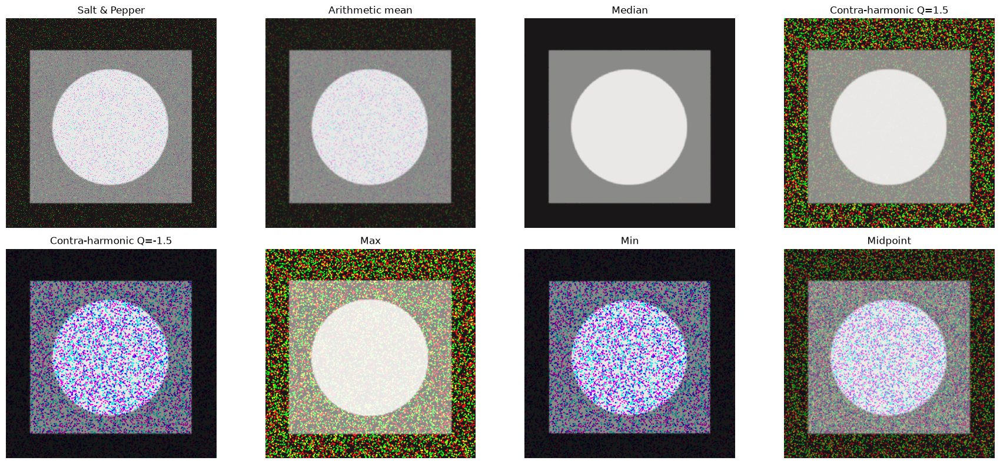

In [10]:
noise_img = noise_sp
k3 = np.ones((3, 3), np.uint8)

plt.figure(figsize=(18, 8))
plt.subplot(241), plt.imshow(noise_img), plt.title('Salt & Pepper')
plt.subplot(242), plt.imshow(cv2.blur(noise_img, (3, 3))), plt.title('Arithmetic mean')
plt.subplot(243), plt.imshow(cv2.medianBlur(noise_img, 3)), plt.title('Median')
plt.subplot(244), plt.imshow(contra_harmonic_mean(noise_img, 3, 1.5)), plt.title('Contra-harmonic Q=1.5')
plt.subplot(245), plt.imshow(contra_harmonic_mean(noise_img, 3, -1.5)), plt.title('Contra-harmonic Q=-1.5')
plt.subplot(246), plt.imshow(cv2.dilate(noise_img, k3)), plt.title('Max')
plt.subplot(247), plt.imshow(cv2.erode(noise_img, k3)), plt.title('Min')
plt.subplot(248), plt.imshow(midpoint_filter(noise_img)), plt.title('Midpoint')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()